In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the IBM Telco Customer Churn dataset
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

# Display the first five rows
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all"))


Dataset shape: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [3]:

# Check recognised missing values in every column
df.isnull().sum()


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [4]:

# Find values that cannot be converted into numbers
total_charges_numeric = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("Invalid or missing TotalCharges values:")
print(total_charges_numeric.isna().sum())

print("\nRows with invalid TotalCharges:")
display(df[total_charges_numeric.isna()])


Invalid or missing TotalCharges values:
11

Rows with invalid TotalCharges:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [5]:

print("Exact duplicate rows:")
print(df.duplicated().sum())

print("\nDuplicate customer IDs:")
print(df["customerID"].duplicated().sum())


Exact duplicate rows:
0

Duplicate customer IDs:
0


In [6]:

# Inspect tenure and charges for the problematic rows
problem_rows = df.loc[
    total_charges_numeric.isna(),
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

display(problem_rows)

print("\nTenure distribution for these rows:")
print(problem_rows["tenure"].value_counts())


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No



Tenure distribution for these rows:
tenure
0    11
Name: count, dtype: int64


In [7]:

# Convert TotalCharges to a numeric column
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Check missing values after conversion
print(df["TotalCharges"].isna().sum())


11


In [8]:

# Replace missing TotalCharges with zero
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Check remaining missing values
print("Missing TotalCharges:",
      df["TotalCharges"].isna().sum())

# Check updated data type
print("Data type:",
      df["TotalCharges"].dtype)


Missing TotalCharges: 0
Data type: float64


In [9]:

# Check the entire dataset for missing values
print("Total missing values:")
print(df.isna().sum().sum())

# Display numerical statistics
display(
    df[["tenure", "MonthlyCharges", "TotalCharges"]].describe()
)

# Check cleaned zero-tenure customers
display(
    df.loc[
        df["tenure"] == 0,
        ["tenure", "MonthlyCharges", "TotalCharges"]
    ]
)


Total missing values:
0


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,0.0
753,0,20.25,0.0
936,0,80.85,0.0
1082,0,25.75,0.0
1340,0,56.05,0.0
3331,0,19.85,0.0
3826,0,25.35,0.0
4380,0,20.00,0.0
5218,0,19.70,0.0
6670,0,73.35,0.0


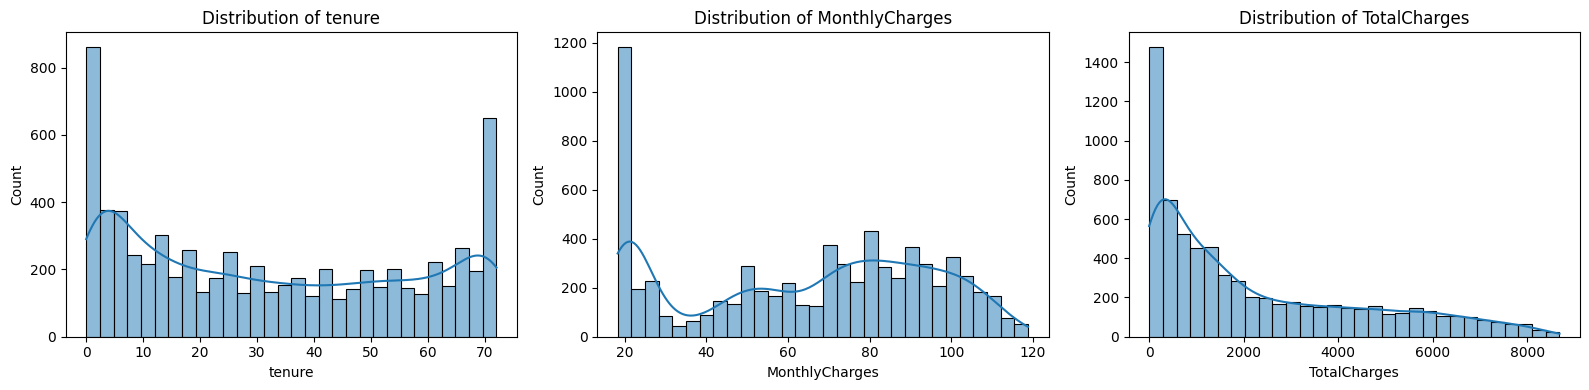

In [10]:

numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for i, col in enumerate(numeric_cols):
    sns.histplot(
        data=df,
        x=col,
        bins=30,
        kde=True,
        ax=axes[i]
    )
    axes[i].set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()


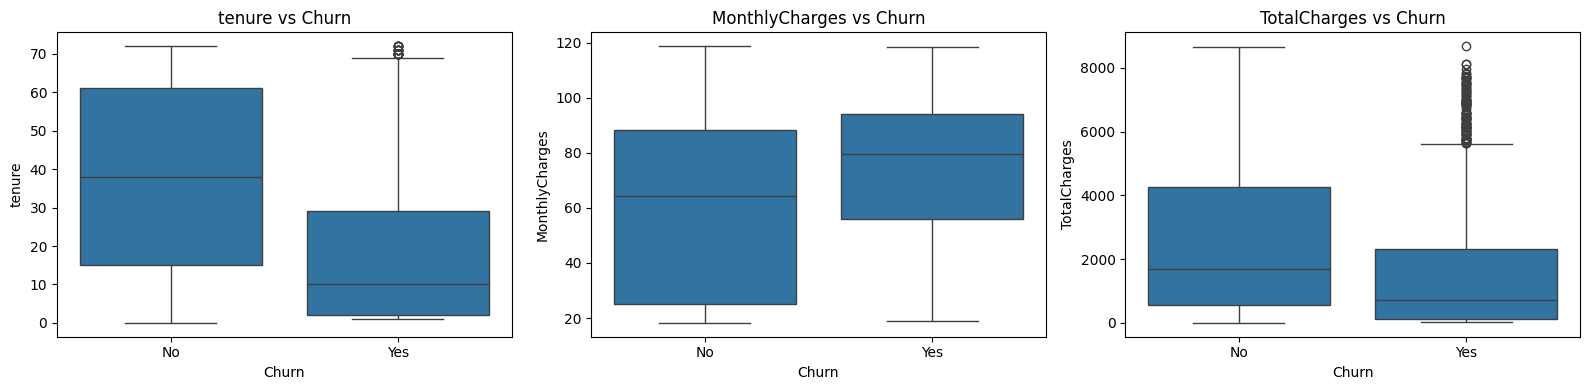

In [11]:

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for i, col in enumerate(numeric_cols):
    sns.boxplot(
        data=df,
        x="Churn",
        y=col,
        ax=axes[i]
    )
    axes[i].set_title(f"{col} vs Churn")

plt.tight_layout()
plt.show()



In [12]:

# Average and median by churn group
summary = df.groupby("Churn")[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].agg(["mean", "median"])

display(summary.round(2))


tenure        MonthlyCharges        TotalCharges         
        mean median           mean median         mean   median
Churn                                                          
No     37.57   38.0          61.27  64.43      2549.91  1679.52
Yes    17.98   10.0          74.44  79.65      1531.80   703.55

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64


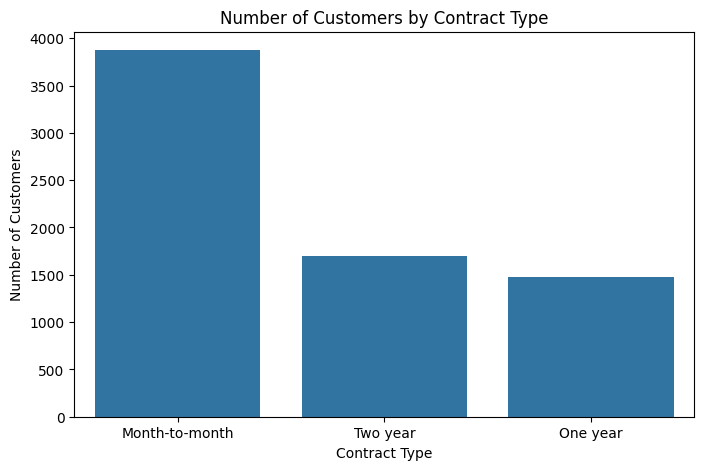

In [13]:

# Count customers by contract type
contract_counts = df["Contract"].value_counts()

print(contract_counts)

# Visualise contract types
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Contract",
    order=df["Contract"].value_counts().index
)

plt.title("Number of Customers by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.show()


In [14]:

# Convert Churn into a numerical indicator
df["Churn_binary"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Calculate churn percentage by contract type
contract_churn = (
    df.groupby("Contract")["Churn_binary"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print("Churn rate by contract type (%):")
display(contract_churn.round(2))


Churn rate by contract type (%):


,Churn_binary
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83


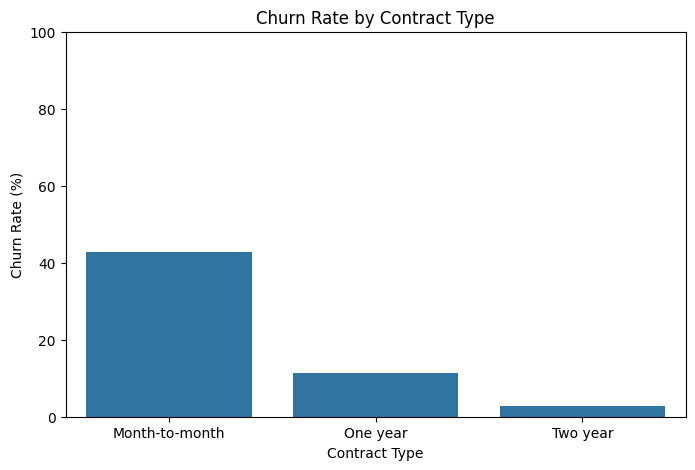

In [15]:

plt.figure(figsize=(8, 5))

sns.barplot(
    x=contract_churn.index,
    y=contract_churn.values
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)

plt.show()


In [16]:

categorical_cols = [
    "InternetService",
    "PaymentMethod",
    "TechSupport"
]

for col in categorical_cols:
    print(f"\nChurn rate by {col}:")

    churn_rates = (
        df.groupby(col)["Churn_binary"]
        .agg(["count", "mean"])
    )

    churn_rates["churn_rate_%"] = (
        churn_rates["mean"] * 100
    )

    churn_rates = churn_rates.sort_values(
        "churn_rate_%",
        ascending=False
    )

    display(
        churn_rates[["count", "churn_rate_%"]].round(2)
    )



Churn rate by InternetService:


,count,churn_rate_%
InternetService,,
Fiber optic,3096,41.89
DSL,2421,18.96
No,1526,7.40



Churn rate by PaymentMethod:


,count,churn_rate_%
PaymentMethod,,
Electronic check,2365,45.29
Mailed check,1612,19.11
Bank transfer (automatic),1544,16.71
Credit card (automatic),1522,15.24



Churn rate by TechSupport:


,count,churn_rate_%
TechSupport,,
No,3473,41.64
Yes,2044,15.17
No internet service,1526,7.40


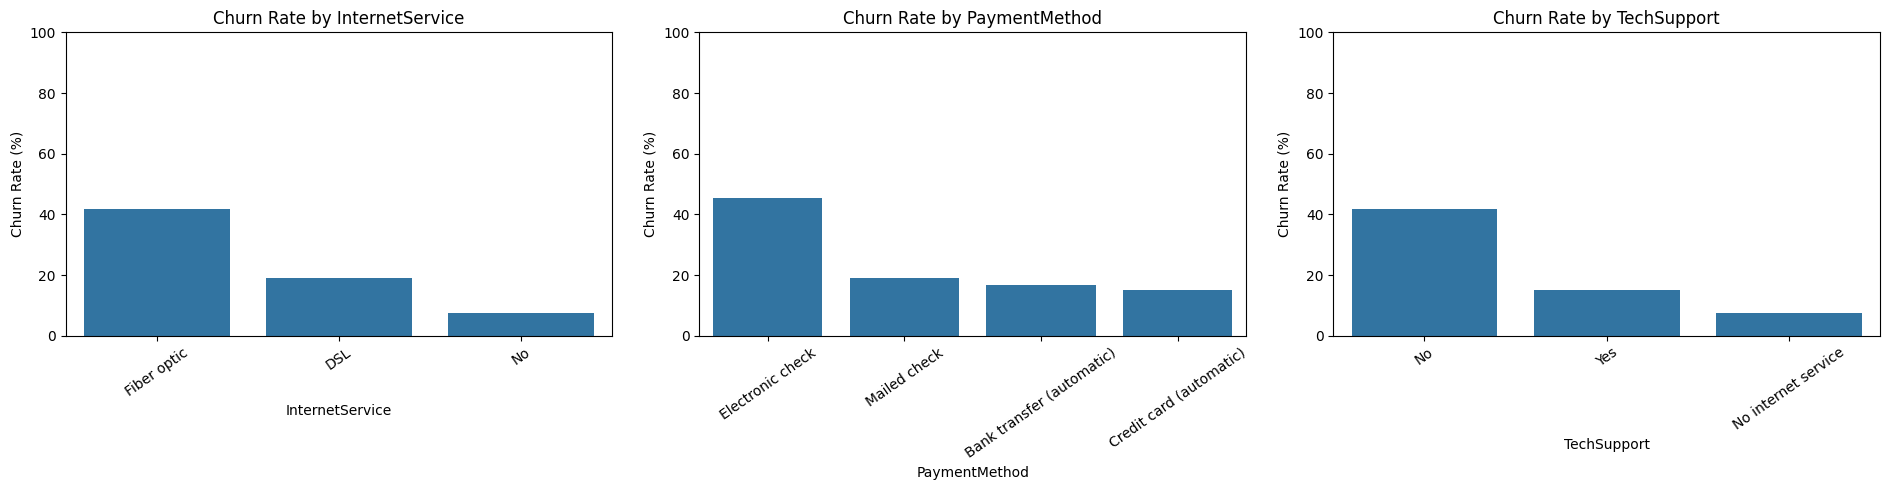

In [17]:

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for i, col in enumerate(categorical_cols):

    rates = (
        df.groupby(col)["Churn_binary"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    sns.barplot(
        x=rates.index,
        y=rates.values,
        ax=axes[i]
    )

    axes[i].set_title(f"Churn Rate by {col}")
    axes[i].set_ylabel("Churn Rate (%)")
    axes[i].set_ylim(0, 100)
    axes[i].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()


In [18]:

# Select numerical variables
corr_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "Churn_binary"
]

# Calculate Pearson correlations
correlation_matrix = df[corr_cols].corr()

# Display results
display(correlation_matrix.round(3))


,tenure,MonthlyCharges,TotalCharges,Churn_binary
tenure,1.000,0.248,0.826,-0.352
MonthlyCharges,0.248,1.000,0.651,0.193
TotalCharges,0.826,0.651,1.000,-0.198
Churn_binary,-0.352,0.193,-0.198,1.000


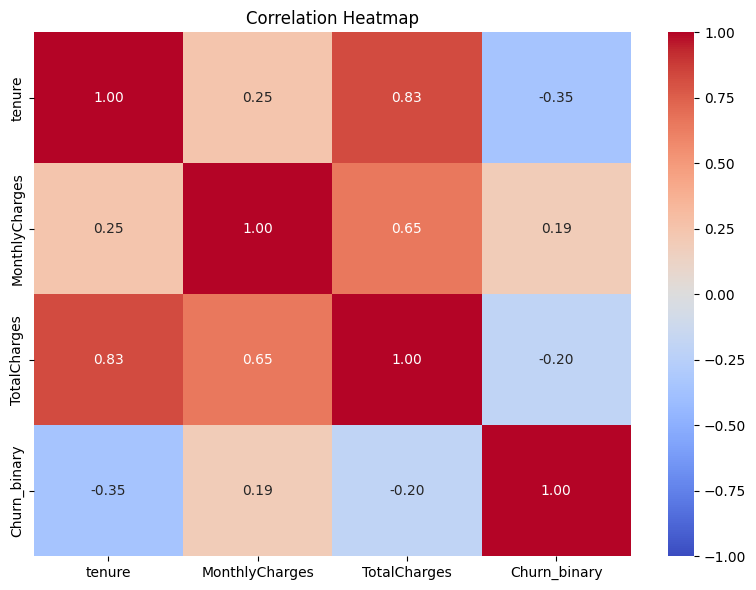

In [19]:

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


In [20]:

# Correlation of numerical features with churn
churn_correlations = (
    correlation_matrix["Churn_binary"]
    .drop("Churn_binary")
    .sort_values()
)

display(churn_correlations.round(3))


,Churn_binary
tenure,-0.352
TotalCharges,-0.198
MonthlyCharges,0.193


In [21]:

# Make a working copy
df_ml = df.copy()

# Feature 1: Historical average monthly spending
df_ml["AvgMonthlySpend"] = np.where(
    df_ml["tenure"] > 0,
    df_ml["TotalCharges"] / df_ml["tenure"].clip(lower=1),
    0
)

# Feature 2: Identify newer customers
df_ml["IsNewCustomer"] = (
    df_ml["tenure"] <= 12
).astype(int)

# Feature 3: Identify internet customers
df_ml["HasInternet"] = (
    df_ml["InternetService"] != "No"
).astype(int)

# Inspect new features
display(
    df_ml[
        [
            "tenure",
            "MonthlyCharges",
            "TotalCharges",
            "AvgMonthlySpend",
            "IsNewCustomer",
            "HasInternet"
        ]
    ].head(10)
)


,tenure,MonthlyCharges,TotalCharges,AvgMonthlySpend,IsNewCustomer,HasInternet
0,1,29.85,29.85,29.850000,1,1
1,34,56.95,1889.50,55.573529,0,1
2,2,53.85,108.15,54.075000,1,1
3,45,42.30,1840.75,40.905556,0,1
4,2,70.70,151.65,75.825000,1,1
5,8,99.65,820.50,102.562500,1,1
6,22,89.10,1949.40,88.609091,0,1
7,10,29.75,301.90,30.190000,1,1
8,28,104.80,3046.05,108.787500,0,1
9,62,56.15,3487.95,56.257258,0,1


In [22]:

# Define target variable
y = df_ml["Churn_binary"]

# Remove target columns and customer identifier
X = df_ml.drop(
    columns=[
        "customerID",
        "Churn",
        "Churn_binary"
    ]
)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())


Feature matrix shape: (7043, 22)
Target shape: (7043,)

Feature columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'AvgMonthlySpend', 'IsNewCustomer', 'HasInternet']


In [23]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (5634, 22)
X_test: (1409, 22)
y_train: (5634,)
y_test: (1409,)


In [24]:

print("Training churn distribution (%):")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting churn distribution (%):")
print(y_test.value_counts(normalize=True) * 100)


Training churn distribution (%):
Churn_binary
0    73.464679
1    26.535321
Name: proportion, dtype: float64

Testing churn distribution (%):
Churn_binary
0    73.456352
1    26.543648
Name: proportion, dtype: float64


In [25]:

# Identify numerical columns
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical columns
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumerical count:", len(numerical_features))
print("Categorical count:", len(categorical_features))


Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'AvgMonthlySpend', 'IsNewCustomer', 'HasInternet']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical count: 7
Categorical count: 15


In [26]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)
from sklearn.impute import SimpleImputer

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [27]:

# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using training parameters
X_test_processed = preprocessor.transform(X_test)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("Original testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)


Original training shape: (5634, 22)
Processed training shape: (5634, 48)
Original testing shape: (1409, 22)
Processed testing shape: (1409, 48)


In [28]:

feature_names = preprocessor.get_feature_names_out()

print("Total processed features:", len(feature_names))

print("\nProcessed feature names:")
for name in feature_names:
    print(name)


Total processed features: 48

Processed feature names:
num__SeniorCitizen
num__tenure
num__MonthlyCharges
num__TotalCharges
num__AvgMonthlySpend
num__IsNewCustomer
num__HasInternet
cat__gender_Female
cat__gender_Male
cat__Partner_No
cat__Partner_Yes
cat__Dependents_No
cat__Dependents_Yes
cat__PhoneService_No
cat__PhoneService_Yes
cat__MultipleLines_No
cat__MultipleLines_No phone service
cat__MultipleLines_Yes
cat__InternetService_DSL
cat__InternetService_Fiber optic
cat__InternetService_No
cat__OnlineSecurity_No
cat__OnlineSecurity_No internet service
cat__OnlineSecurity_Yes
cat__OnlineBackup_No
cat__OnlineBackup_No internet service
cat__OnlineBackup_Yes
cat__DeviceProtection_No
cat__DeviceProtection_No internet service
cat__DeviceProtection_Yes
cat__TechSupport_No
cat__TechSupport_No internet service
cat__TechSupport_Yes
cat__StreamingTV_No
cat__StreamingTV_No internet service
cat__StreamingTV_Yes
cat__StreamingMovies_No
cat__StreamingMovies_No internet service
cat__StreamingMovies_Ye

In [29]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

# Baseline: always predict the most common class
dummy_model = DummyClassifier(strategy="most_frequent")

# Train the baseline
dummy_model.fit(X_train, y_train)

# Predict on training data
dummy_pred_train = dummy_model.predict(X_train)

print("Baseline training accuracy:",
      round(accuracy_score(y_train, dummy_pred_train), 4))

print("Baseline training F1:",
      round(f1_score(y_train, dummy_pred_train), 4))


Baseline training accuracy: 0.7346
Baseline training F1: 0.0


In [30]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Complete pipeline: preprocessing + model
logistic_pipeline = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Train on the original training features
logistic_pipeline.fit(X_train, y_train)

print("Logistic Regression trained successfully!")


Logistic Regression trained successfully!


In [31]:

# Predict churn classes on the training set
y_pred_train = logistic_pipeline.predict(X_train)

# Predict probabilities of churn
y_prob_train = logistic_pipeline.predict_proba(X_train)[:, 1]

print("First 10 predicted classes:")
print(y_pred_train[:10])

print("\nFirst 10 churn probabilities:")
print(y_prob_train[:10].round(3))


First 10 predicted classes:
[0 0 0 0 0 0 0 0 0 0]

First 10 churn probabilities:
[0.332 0.233 0.029 0.071 0.38  0.017 0.175 0.114 0.018 0.055]


In [32]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Logistic Regression — Training Performance")

print("Accuracy:",
      round(accuracy_score(y_train, y_pred_train), 4))

print("Precision:",
      round(precision_score(y_train, y_pred_train), 4))

print("Recall:",
      round(recall_score(y_train, y_pred_train), 4))

print("F1-score:",
      round(f1_score(y_train, y_pred_train), 4))

print("\nClassification Report:")
print(classification_report(y_train, y_pred_train))


Logistic Regression — Training Performance
Accuracy: 0.8076
Precision: 0.6705
Recall: 0.5405
F1-score: 0.5985

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      4139
           1       0.67      0.54      0.60      1495

    accuracy                           0.81      5634
   macro avg       0.76      0.72      0.74      5634
weighted avg       0.80      0.81      0.80      5634



Confusion Matrix:
[[3742  397]
 [ 687  808]]


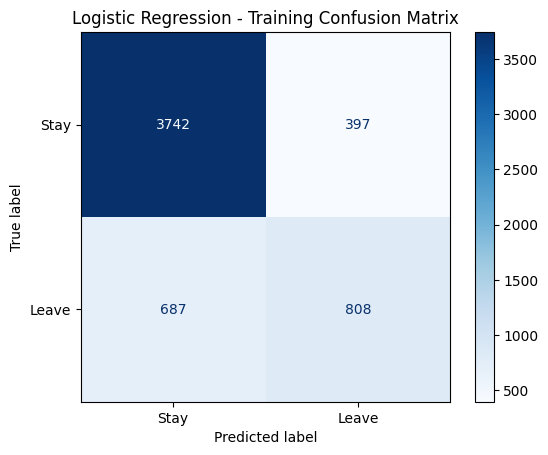

In [33]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Training confusion matrix
cm = confusion_matrix(y_train, y_pred_train)

print("Confusion Matrix:")
print(cm)

# Visualise
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stay", "Leave"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Training Confusion Matrix")
plt.show()


In [34]:

# Extract values from confusion matrix
tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

print("\nCustomers who actually churned:", fn + tp)
print("Churn customers correctly identified:", tp)
print("Churn customers missed:", fn)

print("\nPercentage of churn customers missed:")
print(round(fn / (fn + tp) * 100, 2), "%")


True Negatives: 3742
False Positives: 397
False Negatives: 687
True Positives: 808

Customers who actually churned: 1495
Churn customers correctly identified: 808
Churn customers missed: 687

Percentage of churn customers missed:
45.95 %


In [35]:

from sklearn.model_selection import StratifiedKFold, cross_validate

# Create five stratified folds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate on training data only
cv_results = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    },
    n_jobs=-1
)

# Print mean and standard deviation
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    scores = cv_results[f"test_{metric}"]

    print(
        f"{metric}: Mean={scores.mean():.4f}, "
        f"Std={scores.std():.4f}"
    )


accuracy: Mean=0.8037, Std=0.0101
precision: Mean=0.6624, Std=0.0233
recall: Mean=0.5311, Std=0.0361
f1: Mean=0.5890, Std=0.0269
roc_auc: Mean=0.8460, Std=0.0115


In [36]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

decision_tree_pipeline = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("model", DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=20,
        random_state=42
    ))
])

decision_tree_pipeline.fit(X_train, y_train)

print("Decision Tree trained successfully!")


Decision Tree trained successfully!


In [37]:

from sklearn.ensemble import RandomForestClassifier

random_forest_pipeline = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_pipeline.fit(X_train, y_train)

print("Random Forest trained successfully!")


Random Forest trained successfully!


In [38]:

import pandas as pd
from sklearn.model_selection import cross_validate

models = {
    "Logistic Regression": logistic_pipeline,
    "Decision Tree": decision_tree_pipeline,
    "Random Forest": random_forest_pipeline
}

results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1",
            "roc_auc": "roc_auc"
        },
        n_jobs=1
    )

    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

comparison_df = pd.DataFrame(results)

display(
    comparison_df.sort_values(
        "F1",
        ascending=False
    ).round(4)
)


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.8037,0.6624,0.5311,0.5890,0.8460
2,Random Forest,0.8023,0.6706,0.5043,0.5752,0.8469
1,Decision Tree,0.7934,0.6358,0.5291,0.5745,0.8282


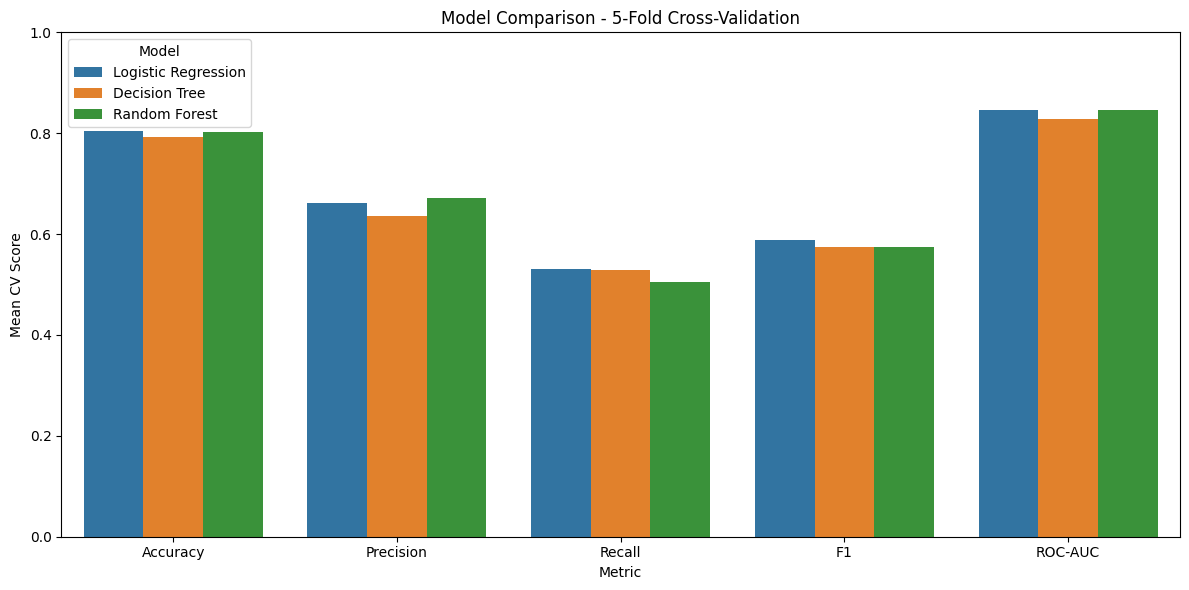

In [39]:

plot_data = comparison_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_data,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Model Comparison - 5-Fold Cross-Validation")
plt.ylabel("Mean CV Score")
plt.ylim(0, 1)
plt.legend(title="Model")

plt.tight_layout()
plt.show()


In [40]:

from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.pipeline import Pipeline

# Fresh Random Forest pipeline
rf_tuning_pipeline = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

# Hyperparameters to explore
param_distributions = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [5, 10, 15, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 3, 5, 10],
    "model__max_features": ["sqrt", "log2"]
}

print("Search space defined successfully!")


Search space defined successfully!


In [41]:

rf_search = RandomizedSearchCV(
    estimator=rf_tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=15,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

rf_search.fit(X_train, y_train)

print("Best parameters:")
print(rf_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(rf_search.best_score_, 4))


Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best parameters:
{'model__n_estimators': 100, 'model__min_samples_split': 10, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': None}

Best cross-validation F1-score:
0.5758


In [42]:

# Convert tuning results to a DataFrame
tuning_results = pd.DataFrame(
    rf_search.cv_results_
)

# Select useful columns
tuning_summary = tuning_results[
    [
        "rank_test_score",
        "mean_test_score",
        "std_test_score",
        "params"
    ]
].sort_values("rank_test_score")

display(tuning_summary.head(10))


,rank_test_score,mean_test_score,std_test_score,params
10,1,0.575789,0.027858,"{'model__n_estimators': 100, 'model__min_sampl..."
12,2,0.573505,0.023353,"{'model__n_estimators': 300, 'model__min_sampl..."
8,3,0.571923,0.026320,"{'model__n_estimators': 300, 'model__min_sampl..."
7,4,0.571723,0.020411,"{'model__n_estimators': 200, 'model__min_sampl..."
9,5,0.568621,0.016978,"{'model__n_estimators': 100, 'model__min_sampl..."
4,6,0.567804,0.026316,"{'model__n_estimators': 200, 'model__min_sampl..."
1,7,0.567156,0.027202,"{'model__n_estimators': 200, 'model__min_sampl..."
13,8,0.565409,0.020898,"{'model__n_estimators': 100, 'model__min_sampl..."
2,9,0.557933,0.021513,"{'model__n_estimators': 200, 'model__min_sampl..."
5,10,0.517236,0.016031,"{'model__n_estimators': 100, 'model__min_sampl..."


In [43]:

original_rf_f1 = comparison_df.loc[
    comparison_df["Model"] == "Random Forest",
    "F1"
].iloc[0]

tuned_rf_f1 = rf_search.best_score_

print("Original Random Forest CV F1:",
      round(original_rf_f1, 4))

print("Tuned Random Forest CV F1:",
      round(tuned_rf_f1, 4))

print("Difference:",
      round(tuned_rf_f1 - original_rf_f1, 4))


Original Random Forest CV F1: 0.5752
Tuned Random Forest CV F1: 0.5758
Difference: 0.0006


In [44]:

from sklearn.model_selection import cross_val_predict

# Out-of-fold probabilities on training data
cv_probabilities = cross_val_predict(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

print("Number of probabilities:", len(cv_probabilities))

print("\nFirst 10 probabilities:")
print(cv_probabilities[:10].round(3))


Number of probabilities: 5634

First 10 probabilities:
[0.369 0.244 0.025 0.069 0.37  0.017 0.167 0.112 0.024 0.059]


In [45]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = np.arange(0.10, 0.91, 0.05)

threshold_results = []

for t in thresholds:

    predictions = (cv_probabilities >= t).astype(int)

    threshold_results.append({
        "Threshold": round(float(t), 2),
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_train, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,Threshold,Precision,Recall,F1
0,0.10,0.4027,0.9425,0.5643
1,0.15,0.4370,0.9117,0.5908
2,0.20,0.4794,0.8582,0.6152
3,0.25,0.5084,0.8107,0.6249
4,0.30,0.5432,0.7652,0.6354
5,0.35,0.5719,0.7130,0.6347
6,0.40,0.6002,0.6569,0.6273
7,0.45,0.6251,0.5900,0.6070
8,0.50,0.6622,0.5311,0.5895
9,0.55,0.6887,0.4662,0.5560


In [46]:

best_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

best_threshold = float(best_row["Threshold"])

print("Best threshold:", best_threshold)
print("Precision:", round(best_row["Precision"], 4))
print("Recall:", round(best_row["Recall"], 4))
print("F1:", round(best_row["F1"], 4))


Best threshold: 0.3
Precision: 0.5432
Recall: 0.7652
F1: 0.6354


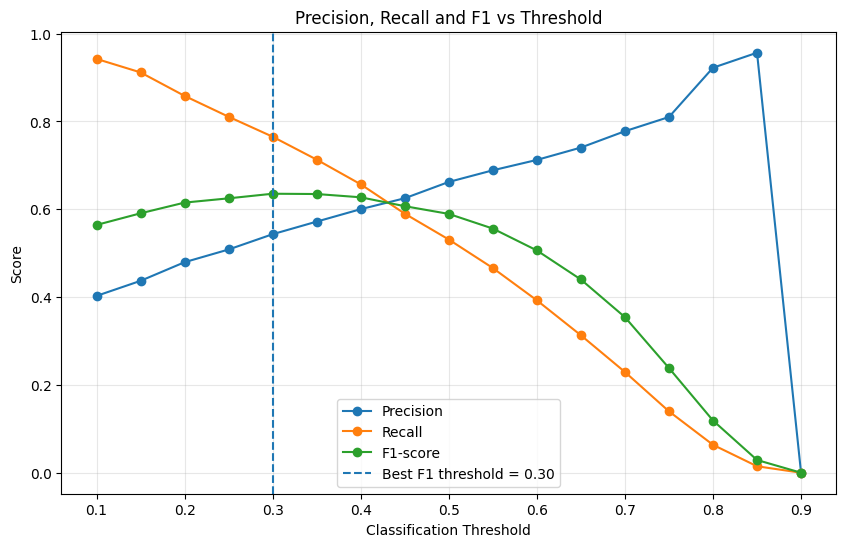

In [47]:

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker="o",
    label="F1-score"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Best F1 threshold = {best_threshold:.2f}"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 vs Threshold")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [48]:

# Predict churn probabilities on unseen test data
test_probabilities = logistic_pipeline.predict_proba(
    X_test
)[:, 1]

# Default threshold
test_pred_default = (
    test_probabilities >= 0.50
).astype(int)

# Selected threshold from training CV
test_pred_optimized = (
    test_probabilities >= best_threshold
).astype(int)

print("Test customers:", len(test_probabilities))
print("Selected threshold:", best_threshold)
print("First 10 probabilities:")
print(test_probabilities[:10].round(3))


Test customers: 1409
Selected threshold: 0.3
First 10 probabilities:
[0.046 0.751 0.06  0.343 0.026 0.551 0.39  0.109 0.004 0.322]


In [49]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

test_results = []

for name, predictions in [
    ("Default 0.50", test_pred_default),
    ("Optimized 0.30", test_pred_optimized)
]:
    test_results.append({
        "Threshold": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, test_probabilities
        )
    })

test_comparison = pd.DataFrame(test_results)

display(test_comparison.round(4))


,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC
0,Default 0.50,0.8034,0.6622,0.5294,0.5884,0.8416
1,Optimized 0.30,0.7559,0.5281,0.7540,0.6211,0.8416


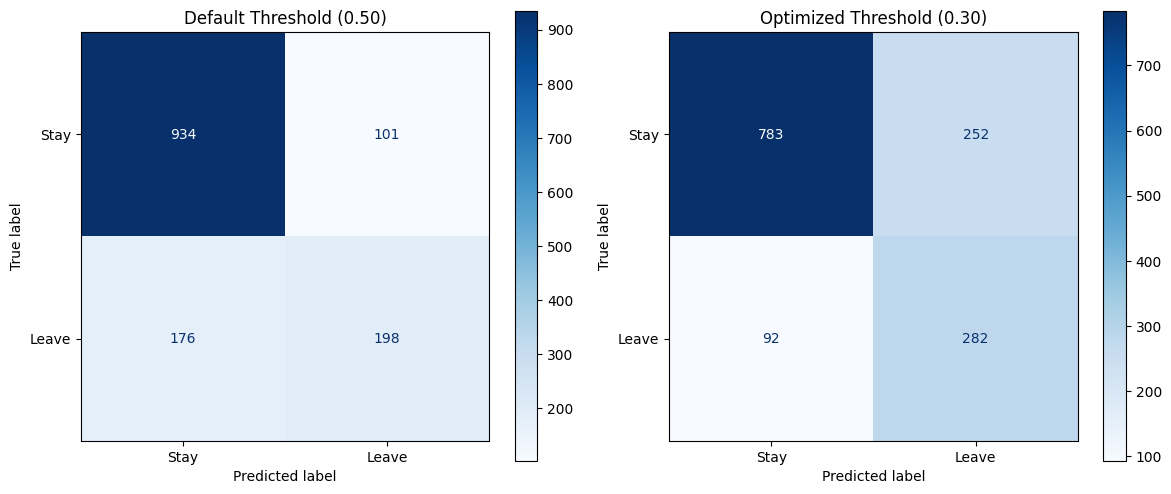

In [50]:

from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, predictions, title in zip(
    axes,
    [test_pred_default, test_pred_optimized],
    ["Default Threshold (0.50)",
     f"Optimized Threshold ({best_threshold:.2f})"]
):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["Stay", "Leave"],
        cmap="Blues",
        values_format="d",
        ax=ax
    )
    ax.set_title(title)

plt.tight_layout()
plt.show()


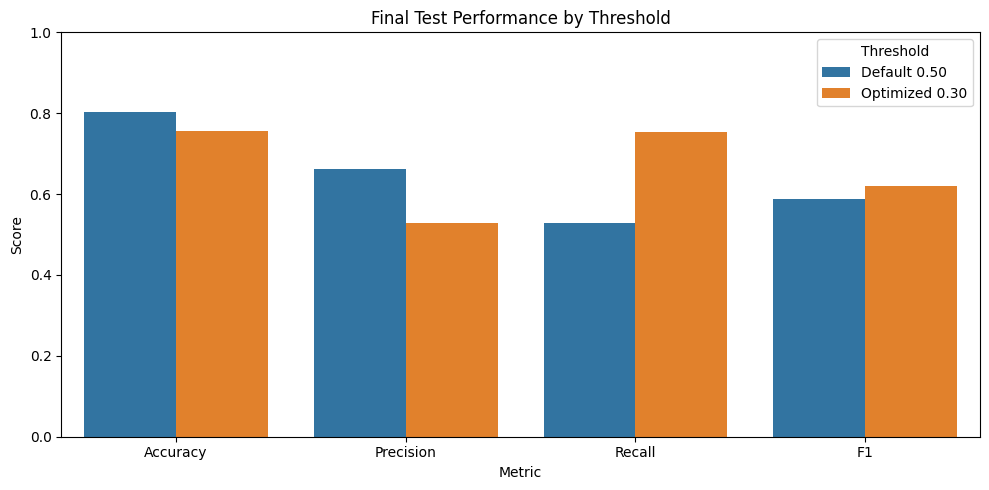

In [51]:

plot_data = test_comparison.melt(
    id_vars="Threshold",
    value_vars=["Accuracy", "Precision", "Recall", "F1"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=plot_data,
    x="Metric",
    y="Score",
    hue="Threshold"
)

plt.title("Final Test Performance by Threshold")
plt.ylim(0, 1)
plt.ylabel("Score")
plt.tight_layout()
plt.show()


In [52]:

# Extract fitted preprocessing and model
fitted_preprocessor = logistic_pipeline.named_steps[
    "preprocessing"
]

fitted_model = logistic_pipeline.named_steps["model"]

# Get processed feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# Get Logistic Regression coefficients
coefficients = fitted_model.coef_[0]

# Create coefficient table
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort coefficients
coef_df = coef_df.sort_values(
    "Coefficient",
    ascending=False
)

display(coef_df.round(4))


,Feature,Coefficient
39,cat__Contract_Month-to-month,0.6366
19,cat__InternetService_Fiber optic,0.5909
6,num__HasInternet,0.3441
5,num__IsNewCustomer,0.2522
3,num__TotalCharges,0.2495
46,cat__PaymentMethod_Electronic check,0.1973
35,cat__StreamingTV_Yes,0.1650
38,cat__StreamingMovies_Yes,0.1650
4,num__AvgMonthlySpend,0.1528
21,cat__OnlineSecurity_No,0.1204


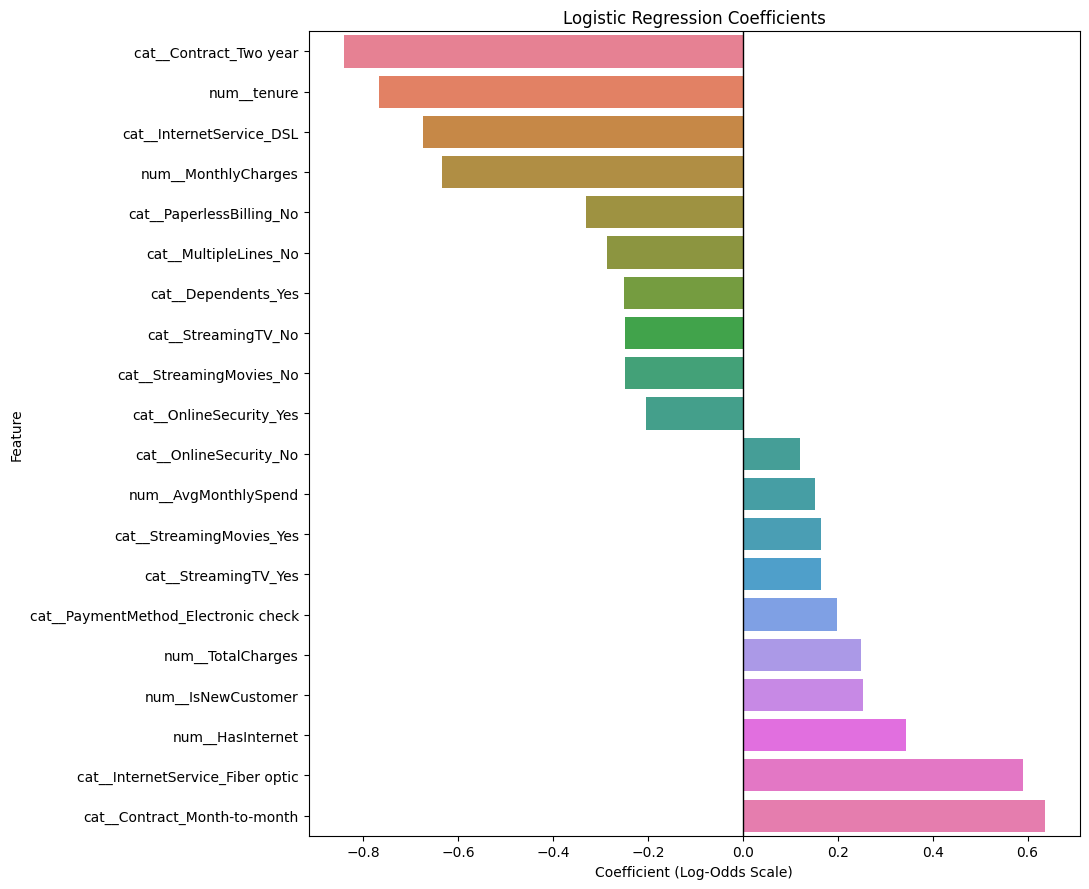

In [53]:

# Select largest positive and negative coefficients
top_positive = coef_df.nlargest(10, "Coefficient")
top_negative = coef_df.nsmallest(10, "Coefficient")

top_features = pd.concat([
    top_negative,
    top_positive
]).sort_values("Coefficient")

plt.figure(figsize=(11, 9))

sns.barplot(
    data=top_features,
    x="Coefficient",
    y="Feature",
    hue="Feature",
    dodge=False,
    legend=False
)

plt.axvline(0, color="black", linewidth=1)

plt.title("Logistic Regression Coefficients")
plt.xlabel("Coefficient (Log-Odds Scale)")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


In [54]:

from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer, f1_score

# Measure feature importance using training data
perm_result = permutation_importance(
    logistic_pipeline,
    X_train,
    y_train,
    scoring=make_scorer(f1_score),
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

display(importance_df.round(4))


,Feature,Importance,Std
4,tenure,0.1576,0.0062
14,Contract,0.1271,0.0073
7,InternetService,0.1077,0.0087
21,HasInternet,0.0396,0.0061
20,IsNewCustomer,0.0261,0.0037
8,OnlineSecurity,0.0244,0.0028
16,PaymentMethod,0.0232,0.0030
19,AvgMonthlySpend,0.0182,0.0026
11,TechSupport,0.0171,0.0031
15,PaperlessBilling,0.0167,0.0050


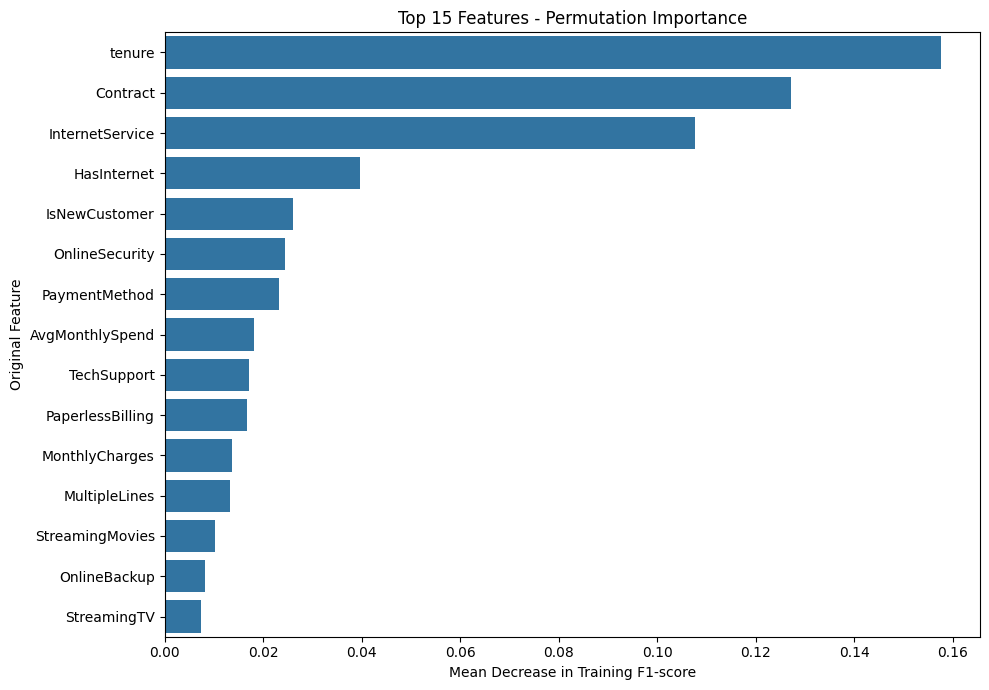

In [55]:

top_15 = importance_df.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_15,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features - Permutation Importance")
plt.xlabel("Mean Decrease in Training F1-score")
plt.ylabel("Original Feature")

plt.tight_layout()
plt.show()


In [57]:

import joblib

# Save trained pipeline and selected threshold
model_package = {
    "pipeline": logistic_pipeline,
    "threshold": best_threshold,
    "feature_columns": X_train.columns.tolist()
}

joblib.dump(
    model_package,
    "customer_churn_model.joblib"
)

print("Model saved successfully!")
print("Selected threshold:", best_threshold)


Model saved successfully!
Selected threshold: 0.3


In [58]:

# Load saved model package
loaded_package = joblib.load(
    "customer_churn_model.joblib"
)

loaded_model = loaded_package["pipeline"]
loaded_threshold = loaded_package["threshold"]

print("Model loaded successfully!")
print("Threshold:", loaded_threshold)
print("Expected features:",
      len(loaded_package["feature_columns"]))


Model loaded successfully!
Threshold: 0.3
Expected features: 22


In [59]:

# Take one existing test customer
sample_customer = X_test.iloc[[0]]

# Predict churn probability
probability = loaded_model.predict_proba(
    sample_customer
)[0, 1]

# Apply saved threshold
prediction = int(probability >= loaded_threshold)

print("Churn probability:", round(probability, 4))
print("Predicted class:", prediction)
print("Prediction:",
      "Leave" if prediction == 1 else "Stay")


Churn probability: 0.0461
Predicted class: 0
Prediction: Stay


In [60]:

from google.colab import files

files.download("customer_churn_model.joblib")



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [61]:

# Export final model evaluation
test_comparison.to_csv(
    "customer_churn_final_results.csv",
    index=False
)

# Export permutation importance
importance_df.to_csv(
    "customer_churn_feature_importance.csv",
    index=False
)

print("Results exported successfully!")


Results exported successfully!
